# D19. Voice Cloning & AI 윤리 — 몇 초면 복제되는 목소리, 어떻게 만들고 어떻게 지킬까

**음성 AI 전문가 과정 (160h) | 4주차 M4 음성 합성(TTS) & Voice Cloning | 4시간**

## 학습 목표
1. **zero-shot 음성 복제**가 무엇이고, 어디에 쓰이며(접근성 · 더빙 · 제작) 어떤 위험(사칭 · 가짜 녹취 · 인증 우회 · 선거 딥페이크)이 있는지 설명한다.
2. 목소리 복제와 관련된 **법 · 제도**(인공지능기본법 표시 의무, 부정경쟁방지법 타목, 공직선거법 제82조의8, 개인정보보호법, EU AI Act 제50조)의 요점을 말한다.
3. **동의 게이트**를 만든다: 화자 인증(WavLM)으로 '같은 사람인지', 받아쓰기(Whisper)로 '동의 문장을 읽었는지' 확인하고, **SHA-256 해시**가 든 동의 기록을 남긴다.
4. Chatterbox로 **내 목소리를 zero-shot 복제**하고, 참고 음성 길이(3 · 6 · 10초)에 따라 닮은 정도가 어떻게 변하는지 잰다.
5. **화자 인증이 복제를 막을 수 있는지** 실험하고, 목소리 인증만으로는 위험한 이유를 설명한다.
6. **워터마크**를 잡음 · 전화 · MP3 · 속도 · 음높이 변형에 노출해 견고성을 재고, 고지 · 워터마크 · 로그 · **철회**까지 갖춘 '책임 있는 복제 함수'를 만든다.

## 오늘의 실습 흐름
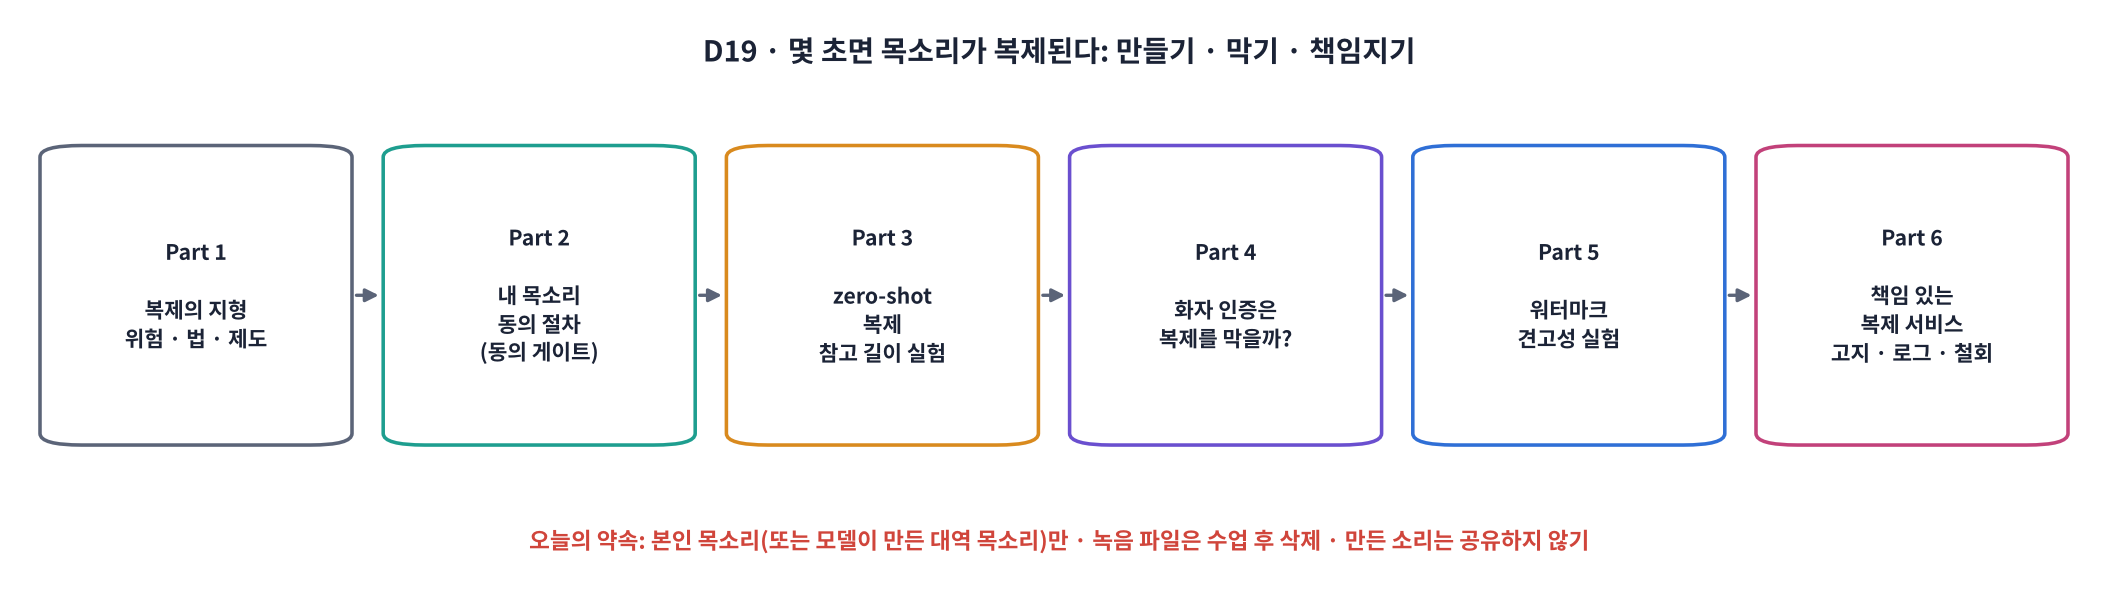

| 교시 | 내용 | 실습 |
|---|---|---|
| 1교시 | 복제의 쓰임과 위험, 법 · 제도, 설치, 화자 인증 도구 | Part 0 ~ 2 앞부분, 워크시트 1교시 |
| 2교시 | 내 목소리 녹음, 동의 게이트 · 동의 기록, zero-shot 복제, 참고 길이 실험 | Part 2 ~ 3, 워크시트 2교시 |
| 3교시 | 화자 인증 vs 복제, 워터마크 견고성 실험 | Part 4 ~ 5, 워크시트 3교시 |
| 4교시 | 책임 있는 복제 함수(고지 · 차단 · 워터마크 · 로그 · 철회), 녹음 삭제, 정리 | Part 6 ~ 7, 워크시트 4교시 · 노션 제출 |

## 오늘의 수업 자료
| 자료 | 링크 | 언제 쓰나요 |
|---|---|---|
| 🎬 인터랙티브 애니메이션 | [animation.html](https://imguru-mooc.github.io/AI_Voice/day19/animation.html) | 각 Part 설명을 볼 때 (Part마다 바로가기 링크가 있습니다) |
| 📝 개념 워크시트 | [worksheet.html](https://imguru-mooc.github.io/AI_Voice/day19/worksheet.html) | 각 교시 끝에 해당 탭 10문항 (4교시 × 10문항), 오답 캡처 → 노션 |

## 이 노트북 사용법
- ▶️ 일반 코드 셀은 위에서부터 차례로 실행합니다. `!`로 시작하는 줄은 리눅스 명령입니다.
- 🧩 **빈칸 실습** 셀은 `____`(밑줄 4개)를 지우고 알맞은 값을 채운 뒤 실행합니다. 마지막 줄에서 ✅ 또는 ❌로 결과를 알려줍니다. 🔑 **정답 및 해설 보기**를 클릭하면 정답이 펼쳐집니다.
- 🎧 표시가 있는 셀은 **소리를 들어 보는** 셀입니다. 🎙️ 표시는 **마이크로 녹음**하는 셀입니다.

| 표시 | 뜻 |
|---|---|
| 💬 **쉽게 말하면** | 그 절의 내용을 한 문장으로 |
| 🍎 **비유** | 일상의 장면으로 바꿔 보기 |
| 👣 **한 단계씩** | 무슨 일이 어떤 순서로 일어나는지 |
| 📐 **핵심 식 하나** | 꼭 기억할 식 하나 |
| ❓ **생각해 보기** | 스스로 답해 보고 펼쳐서 확인 |
| 🎧 **들어 보기** | 합성 결과를 귀로 비교 |

> 🤝 **오늘의 약속 (실습 전에 꼭 읽기)**
> 1. 복제하는 목소리는 **본인 목소리**이거나, 녹음이 싫다면 **모델이 만든 대역 목소리**(`USE_MIC = False`)만 씁니다. 다른 사람(가족 · 친구 · 유명인)의 목소리는 쓰지 않습니다.
> 2. 만든 소리는 **노트북 밖으로 공유하지 않습니다**(메신저 · SNS · 과제 제출 포함). 제출은 표와 숫자만 합니다.
> 3. 수업이 끝나면 Part 7의 **삭제 셀**로 녹음 · 복제 파일을 지웁니다.
> 4. 이 노트북의 법 · 제도 내용은 **수업용 요약**이며 법률 자문이 아닙니다. 서비스를 만들 때는 전문가의 검토를 받으세요.
>
> ⚙️ **런타임 → 런타임 유형 변경 → T4 GPU**를 선택하세요. 🎙️ 녹음은 Colab 브라우저의 마이크 권한이 필요합니다.

> 🎬 **애니메이션 D19-1:** [오늘의 흐름](https://imguru-mooc.github.io/AI_Voice/day19/animation.html#flow) — Part 1~6 로드맵

## Part 0. 준비

> 🛠️ **버전 충돌 방지 (D18과 같은 방식)**: Chatterbox와 워터마크 라이브러리(Perth)를 **GitHub 커밋으로 고정**하고 `--no-deps`로 본체만 넣습니다. 화자 인증 모델(WavLM)은 Colab에 이미 있는 `transformers`로 불러오므로 추가 설치가 없습니다.

In [ ]:
# 📦 설치: Colab 기본 패키지 버전은 그대로 고정하고 필요한 것만 추가 (런타임 재시작 불필요, 2 ~ 3분)
import importlib.metadata as md
KEEP = ["torch", "torchaudio", "torchvision", "torchcodec", "transformers", "tokenizers", "huggingface-hub", "datasets",
        "accelerate", "diffusers", "numpy", "scipy", "librosa", "numba", "safetensors", "protobuf", "requests",
        "click", "filelock", "rich", "typer", "pydantic"]
pins = []
for p in KEEP:
    try:
        pins.append(f"{p}=={md.version(p)}")
    except md.PackageNotFoundError:
        pass
open("colab_constraints.txt", "w").write("\n".join(pins) + "\n")
print("고정한 버전:", ", ".join(pins))

CB = "chatterbox-tts @ git+https://github.com/resemble-ai/chatterbox@5de7a54aa4e5e2baadb0182dde554908b48b85c2"
PERTH = "resemble-perth @ git+https://github.com/resemble-ai/Perth@ff1c8ac55a976971245cdd53c18d6131ca00d993"
!pip install -q -c colab_constraints.txt --no-deps "{CB}" "{PERTH}"
!pip install -q -c colab_constraints.txt s3tokenizer "conformer==0.3.2" pykakasi pyloudnorm omegaconf jiwer
!apt-get -qq -y install ffmpeg > /dev/null
print("✅ 설치 완료")

In [ ]:
import os, sys, re, io, json, time, copy, base64, random, hashlib, shutil, subprocess, warnings, logging
from datetime import datetime, timedelta
import numpy as np
import pandas as pd
import soundfile as sf
import librosa
import torch
import jiwer
import matplotlib.pyplot as plt
from IPython.display import Audio, display
import importlib.metadata as md
warnings.filterwarnings("ignore")
logging.getLogger("chatterbox").setLevel(logging.ERROR)

GPU = torch.cuda.is_available()
DEVICE = "cuda" if GPU else "cpu"
SR = 24000                                              # Chatterbox 출력 · 오늘 기본 샘플링 레이트
WORK = "voice19"                                        # 오늘 만드는 모든 소리 파일은 이 폴더에만 (Part 7에서 삭제)
os.makedirs(WORK, exist_ok=True)
print(" · ".join(f"{p} {md.version(p)}" for p in ["torch", "transformers", "chatterbox-tts", "resemble-perth"]))
print("GPU:", torch.cuda.get_device_name(0) if GPU else "없음 ⚠️ T4로 바꾸세요")

def check(cond, hint="빈칸을 다시 확인하세요."):
    print("✅ 정답입니다! 🎉" if cond else f"❌ {hint}")

def set_seed(s=0):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if GPU: torch.cuda.manual_seed_all(s)

def to_np(y):
    y = y.detach().cpu().numpy() if torch.is_tensor(y) else np.asarray(y)
    return y.reshape(-1).astype(np.float32)

def play(y, sr=SR, label=""):
    y = to_np(y)
    print(f"🎧 {label}  ({len(y) / sr:.2f}초)")
    display(Audio(y, rate=sr))

def load(path, sr=SR):
    return librosa.load(path, sr=sr)[0]

## Part 1. 복제의 지형: 쓰임 · 위험 · 법

> 💬 **쉽게 말하면**: D18에서 '참고 음성'으로 말투를 옮겼습니다. 같은 기능이 **목소리 자체**를 옮기면 **음성 복제(voice cloning)** 입니다. 요즘 모델은 **학습 없이(zero-shot)** 3 ~ 10초짜리 녹음만으로 비슷한 목소리를 냅니다. 그래서 '누구의 목소리를, 누구의 허락으로, 어디에 쓰는가'가 기술만큼 중요해졌습니다.

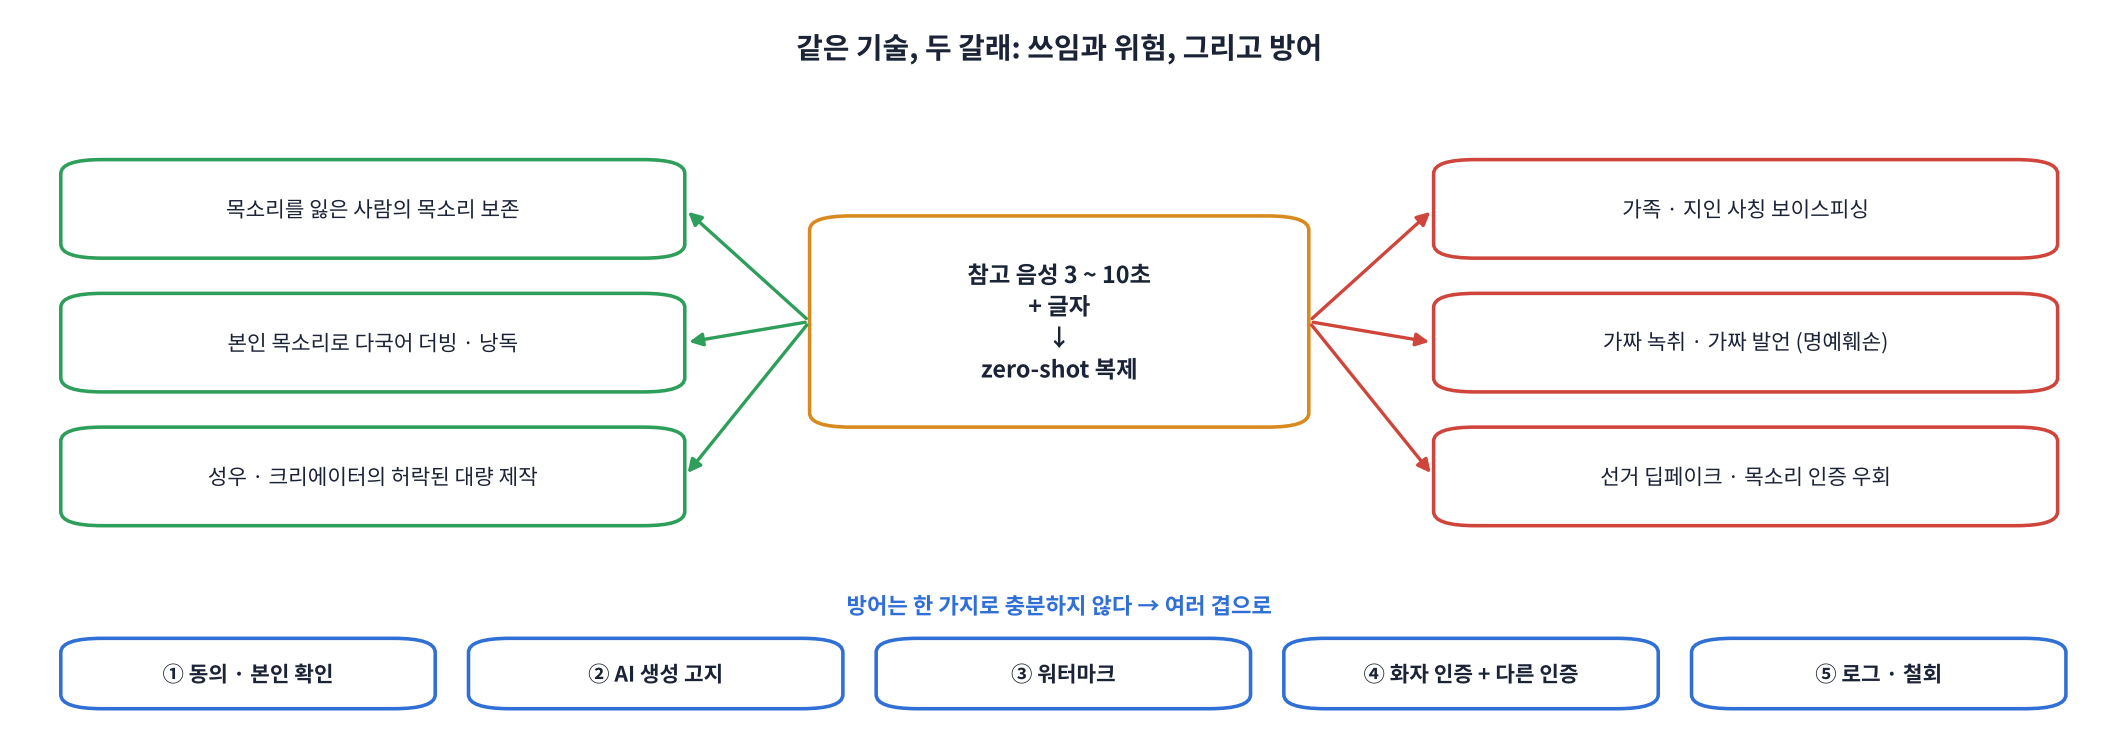

| 방식 | 필요한 것 | 예 | 특징 |
|---|---|---|---|
| **zero-shot** | 참고 음성 3 ~ 10초 (+ F5 등은 대본) | Chatterbox, F5-TTS, CosyVoice | 학습 없음 · 즉시 · 품질은 참고 음성에 좌우 |
| **fine-tuning** | 그 사람 녹음 수십 분 ~ 수 시간 | VITS · XTTS 등 추가 학습 | 더 닮음 · 시간 · GPU 필요 |
| **음성 변환(VC)** | 원본 말소리 + 목표 목소리 | Chatterbox VC, RVC | 말한 내용 · 억양은 그대로, 목소리만 바꿈 → 실시간 사칭에 악용 가능 |

### 1-1. 법 · 제도 (2026년 10월 기준 요약 · 법률 자문 아님)
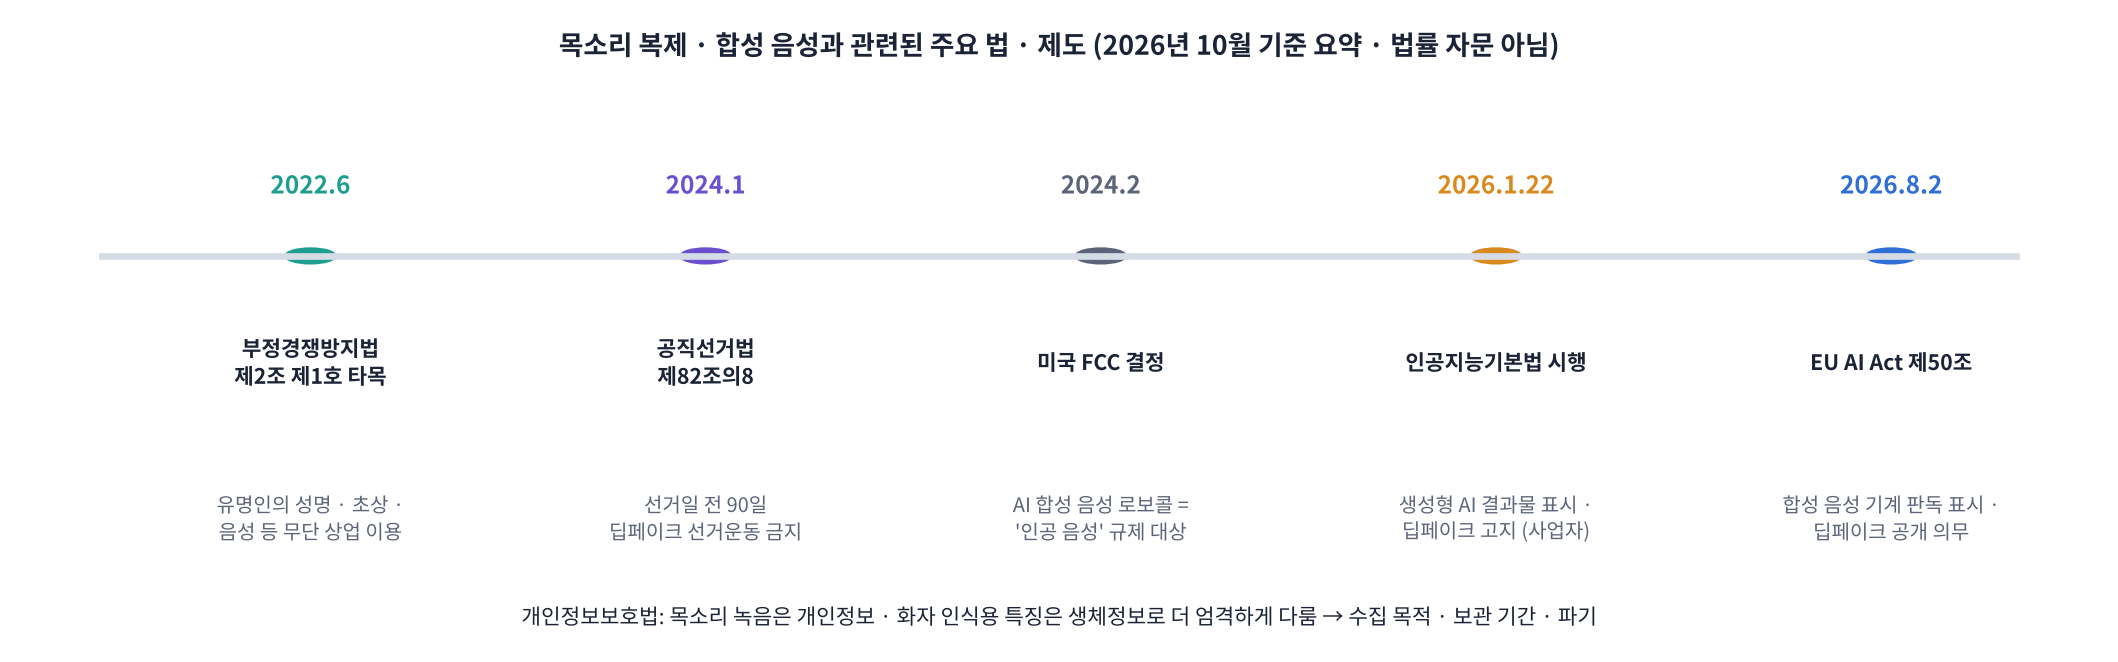

| 법 · 제도 | 핵심 | 오늘 실습과의 연결 |
|---|---|---|
| **인공지능기본법** (2026.1.22 시행) | 생성형 AI로 만든 결과물임을 **표시**, 실제와 구분이 어려운 결과물(딥페이크)은 이용자가 **분명히 알 수 있게 고지** · 의무 대상은 **AI 사업자**(일반 이용자 아님) · 시행 초기 1년 이상 계도 중심 | Part 6: 음성 앞 **고지 문구** + **워터마크** |
| **부정경쟁방지법** 제2조 제1호 **타목** (2022.6 시행) | 널리 알려진 사람의 **성명 · 초상 · 음성 · 서명** 등 인적 식별 표지를 허락 없이 영리에 사용 금지 | 유명인 목소리 복제 상품 ✗ |
| **공직선거법** 제82조의8 (2024.1 시행) | 선거일 전 **90일**부터 딥페이크 영상 · **음향** 등을 이용한 선거운동 금지 | 정치인 목소리 복제 ✗ |
| **개인정보보호법** | 목소리 녹음은 **개인정보**, 사람을 알아보려고 뽑은 화자 특징은 **생체정보**로 더 엄격하게 | Part 2: 목적 · 보관 기간 · 파기 · Part 7 삭제 |
| **EU AI Act 제50조** (2026.8.2 적용) | 합성 음성에 **기계가 읽을 수 있는 표시**(워터마크 등) · 딥페이크는 공개 의무 · 위반 시 최대 1,500만 유로 또는 매출 3% | Part 5: 워터마크 견고성 |
| **미국 FCC 결정** (2024.2) | AI로 만든 목소리를 쓴 자동 전화(로보콜)도 '인공 음성' 규제 대상 | 전화 사칭 차단 |

> 🍎 **비유: 인감도장.** 목소리는 얼굴처럼 '나'를 나타내는 표지이고, 은행 · 가족은 목소리로 사람을 알아봅니다. 목소리 복제는 **인감도장을 복사하는 기계**와 같습니다. 기계를 만드는 것은 불법이 아니지만, 누구의 도장을 언제 찍는지는 **본인의 허락과 기록**이 있어야 합니다.

**❓ 생각해 보기**: 목소리를 잃어 가는 환자가 건강할 때의 녹음으로 자기 목소리를 보존하려 합니다. 이 경우에도 동의 · 기록 · 워터마크가 필요할까요?

<details>
<summary>답 보기</summary>

필요합니다. 본인이 원하는 좋은 쓰임이라도 ① 본인 동의와 **목적 · 범위**(병원 의사소통용, 가족만)를 기록해야 나중에 다른 사람이 그 목소리를 다른 목적으로 쓰는 것을 막을 수 있고, ② 워터마크는 그 목소리로 만든 소리가 **녹음이 아니라 합성**이라는 사실을 남겨 오해(예: 유언 녹음으로 오인)를 막습니다. 좋은 쓰임과 나쁜 쓰임은 **같은 기술**이라, 안전장치는 쓰임과 무관하게 기본으로 둡니다.

</details>

> 🎬 **애니메이션 D19-2:** [이 사용은 괜찮을까?](https://imguru-mooc.github.io/AI_Voice/day19/animation.html#risk) — 시나리오를 골라 허용 · 조건부 · 금지와 관련 법 · 필요한 안전장치 보기
> 🎬 **애니메이션 D19-3:** [법 · 제도 타임라인](https://imguru-mooc.github.io/AI_Voice/day19/animation.html#law) — 시점을 눌러 핵심 내용과 실습 연결 보기

## Part 2. 내 목소리와 동의 게이트

> 💬 **쉽게 말하면**: 서비스가 "이 목소리를 복제해도 된다"고 판단하려면 두 가지를 확인해야 합니다. ① **같은 사람**: 동의 녹음과 복제에 쓸 녹음의 화자가 같은가(**화자 인증**) ② **그 내용에 동의**: 정해진 동의 문장을 실제로 읽었는가(**받아쓰기**). 둘 다 통과하면 **동의 기록**을 남기고, 기록에는 녹음의 **해시(지문)** 를 넣어 나중에 바꿔치기를 막습니다.

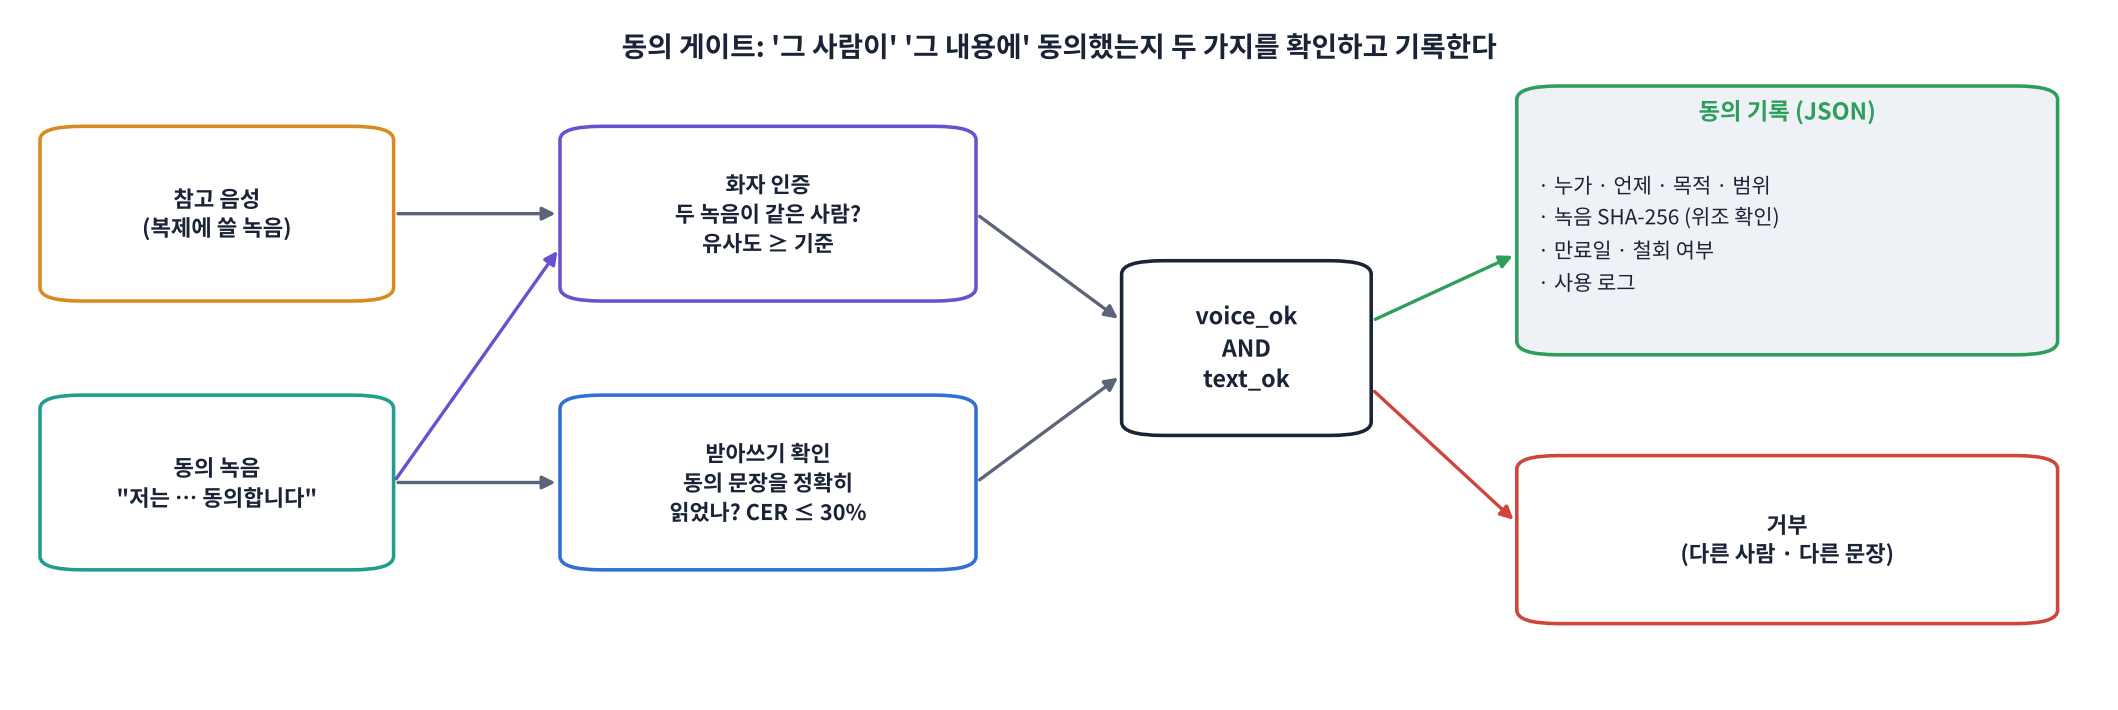

👣 **화자 인증(speaker verification)이 하는 일**
1. 녹음을 16 kHz로 바꿔 WavLM 모델에 넣습니다(D6의 자기지도 학습 음성 모델 계열).
2. 모델이 그 사람의 **목소리 특징 벡터(x-vector, 512차원)** 를 냅니다. 말한 **내용과 상관없이** 목소리 결을 담도록 학습했습니다.
3. 두 벡터의 길이를 1로 맞추고(정규화) 내적 = **코사인 유사도**를 구합니다.
4. 유사도 ≥ **기준(threshold)** 이면 같은 사람으로 판정합니다. 공개 예제들은 0.80 ~ 0.86 정도를 쓰지만, **최적 기준은 마이크 · 언어 · 데이터마다 다릅니다.**

> 📐 **핵심 식 하나: 유사도 = (e₁ ÷ ‖e₁‖) · (e₂ ÷ ‖e₂‖)** — 1이면 같은 방향(같은 목소리), 0이면 무관

> 🎬 **애니메이션 D19-4:** [동의 게이트 시뮬레이터](https://imguru-mooc.github.io/AI_Voice/day19/animation.html#consent) — 화자 유사도와 받아쓰기 오류율을 바꿔 통과 · 거부가 어떻게 정해지는지 보기

### 2-1. 도구 준비: Chatterbox · Whisper · WavLM 화자 인증
처음 실행하면 모델 세 개를 내려받습니다(Chatterbox 약 3 GB, Whisper small 약 1 GB, WavLM 약 0.4 GB · 3 ~ 4분).

In [ ]:
from chatterbox.mtl_tts import ChatterboxMultilingualTTS
model = ChatterboxMultilingualTTS.from_pretrained(device=DEVICE, t3_model="v3")
BUILTIN = copy.deepcopy(model.conds)                    # 모델 기본 목소리 조건 (언제든 되돌리기용)

from transformers import WhisperProcessor, WhisperForConditionalGeneration
ASR_NAME = "openai/whisper-small" if GPU else "openai/whisper-tiny"
asr_proc = WhisperProcessor.from_pretrained(ASR_NAME)
asr = WhisperForConditionalGeneration.from_pretrained(ASR_NAME).to(DEVICE).eval()

def transcribe(y, sr=SR, language="korean"):
    x = librosa.resample(to_np(y), orig_sr=sr, target_sr=16000)
    feats = asr_proc.feature_extractor(x, sampling_rate=16000, return_tensors="pt").input_features.to(DEVICE)
    with torch.no_grad():
        ids = asr.generate(input_features=feats, language=language, task="transcribe", max_new_tokens=128)
    return asr_proc.batch_decode(ids, skip_special_tokens=True)[0].strip()

def cer(ref, hyp):                                      # 공백 · 문장 부호를 빼고 글자 오류율(0 ~ 1)
    f = lambda s: re.sub(r"[^\w]", "", s)
    return jiwer.cer(f(ref), f(hyp) or "∅")
print("✅ Chatterbox · Whisper 준비")

### 🧩 빈칸 실습 1 · 2: 화자 인증 함수 만들기
- 빈칸 1: `WavLMForXVector`의 출력에서 **화자 벡터**가 들어 있는 속성 이름 (`XVectorOutput.____`)
- 빈칸 2: `same_speaker()`가 비교할 **기준 변수**

확인은 '같은 소리끼리는 유사도 1', '기준보다 높으면 같은 사람'으로 합니다.

In [ ]:
# 🧩 빈칸 실습 1 · 2
from transformers import AutoFeatureExtractor, AutoModelForAudioXVector
SV_NAME = "microsoft/wavlm-base-plus-sv"
sv_fe = AutoFeatureExtractor.from_pretrained(SV_NAME)
sv = AutoModelForAudioXVector.from_pretrained(SV_NAME).to(DEVICE).eval()

def embed(y, sr=SR):
    y16 = librosa.resample(to_np(y), orig_sr=sr, target_sr=16000)
    x = sv_fe(y16, sampling_rate=16000, return_tensors="pt").to(DEVICE)
    with torch.no_grad():
        e = sv(**x).____                                                                  # 빈칸 1
    return torch.nn.functional.normalize(e, dim=-1).cpu()

def sim(a, b, sr_a=SR, sr_b=SR):
    return float((embed(a, sr_a) * embed(b, sr_b)).sum())

SV_THRESHOLD = 0.86                                      # 예시 기준 (데이터마다 다시 정해야 함)
def same_speaker(score):
    return score >= ____                                                                  # 빈칸 2

probe = librosa.chirp(fmin=120, fmax=400, sr=SR, duration=2.0) * 0.3
e = embed(probe)
print("화자 벡터 모양:", tuple(e.shape), "· 자기 자신과의 유사도:", round(sim(probe, probe), 4))
check(e.ndim == 2 and e.shape[0] == 1 and abs(sim(probe, probe) - 1) < 1e-4 and same_speaker(0.95) and not same_speaker(0.5),
      hint="빈칸 1 = embeddings, 빈칸 2 = SV_THRESHOLD")

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
e = sv(**x).embeddings
return score >= SV_THRESHOLD
```

**해설**: `WavLMForXVector`의 출력(`XVectorOutput`)에는 분류용 `logits`와 화자 벡터 `embeddings`가 있습니다. 화자 인증에는 `embeddings`(이 모델은 512차원)를 씁니다. 길이를 1로 정규화한 뒤 곱해서 더하면(내적) 코사인 유사도가 됩니다. 기준값을 코드 곳곳에 숫자로 쓰지 않고 **변수 하나**로 두면, 나중에 내 데이터로 기준을 다시 정할 때 한 곳만 바꾸면 됩니다. 실제 서비스는 '같은 사람 쌍'과 '다른 사람 쌍'의 점수 분포를 모아 **오인식(FAR)과 거부(FRR)가 같아지는 점(EER)** 근처로 기준을 정합니다.

</details>

### 2-2. 🎙️ 녹음하기 (또는 대역 목소리)
세 가지를 녹음합니다. 화면에 문장이 나오면 **평소 목소리로** 읽으세요(조용한 곳, 입과 마이크 사이 한 뼘).

| 파일 | 문장 | 쓰임 |
|---|---|---|
| `ref.wav` (12초) | 자유 낭독 문장 | 복제에 쓸 **참고 음성** |
| `heldout.wav` (7초) | 다른 문장 | 복제가 '진짜 나'와 얼마나 닮았는지 비교할 **확인용** |
| `consent.wav` (6초) | 동의 문장 | **동의 게이트** |

> 🔒 녹음이 불편하면 `USE_MIC = False`로 두세요. 모델 기본 목소리로 만든 **대역 목소리**로 똑같이 실습합니다. '다른 사람' 목소리는 항상 대역(기본 목소리를 음높이로 바꿔 참고 음성으로 만든 새 목소리)을 씁니다. 실제 다른 사람의 녹음은 쓰지 않습니다.

In [ ]:
USE_MIC = True                                           # False: 녹음 없이 '대역 목소리'로 실습

REF_TEXT = "안녕하세요. 저는 오늘 음성 인공지능 수업에서 목소리 복제와 윤리를 배우고 있습니다. 창밖에 햇살이 좋아서 기분이 좋네요."
HELD_TEXT = "목소리는 지문처럼 사람마다 다르지만, 몇 초만 있으면 흉내 낼 수 있습니다."
CONSENT_TEXT = "저는 오늘 실습에서 제 목소리를 복제하는 데 동의합니다."
SCRIPTS = {"ref": (REF_TEXT, 12), "heldout": (HELD_TEXT, 7), "consent": (CONSENT_TEXT, 6)}

RECORD_JS = '''
window.recordOne = async function(text, sec) {
  const box = document.createElement('div');
  box.style.cssText = 'font:18px sans-serif;padding:12px 14px;border:2px solid #1E9E8F;border-radius:10px;margin:6px 0';
  document.body.appendChild(box);
  box.innerHTML = '🎙️ 준비 … <b>' + text + '</b>';
  const stream = await navigator.mediaDevices.getUserMedia({audio: true});
  await new Promise(r => setTimeout(r, 1200));
  const rec = new MediaRecorder(stream); const chunks = [];
  rec.ondataavailable = e => chunks.push(e.data);
  rec.start(); box.innerHTML = '🔴 녹음 중 (' + sec + '초) <b>' + text + '</b>';
  await new Promise(r => setTimeout(r, sec * 1000));
  rec.stop(); await new Promise(r => rec.onstop = r); stream.getTracks().forEach(t => t.stop());
  box.innerHTML = '✅ ' + text;
  const b = new Uint8Array(await new Blob(chunks).arrayBuffer()); let s = '';
  for (let i = 0; i < b.length; i += 8192) s += String.fromCharCode.apply(null, b.subarray(i, i + 8192));
  return btoa(s);
};
'''

def to_wav(src, dst):                                   # 어떤 형식이든 24 kHz 모노 WAV로 (D15와 같은 ffmpeg)
    subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", src, "-ac", "1", "-ar", str(SR), dst], check=True)

try:
    from google.colab import output as colab_output
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

def standin(text, seed):                                # 대역 목소리: 모델 기본 목소리
    model.conds = copy.deepcopy(BUILTIN); set_seed(seed)
    return to_np(model.generate(text, language_id="ko"))

if USE_MIC and IN_COLAB:
    from IPython.display import Javascript
    display(Javascript(RECORD_JS))
    for name, (text, sec) in SCRIPTS.items():
        b64 = colab_output.eval_js(f"recordOne({json.dumps(text)}, {sec})")
        open(f"{WORK}/{name}.webm", "wb").write(base64.b64decode(b64))
        to_wav(f"{WORK}/{name}.webm", f"{WORK}/{name}.wav"); os.remove(f"{WORK}/{name}.webm")
    VOICE_KIND = "내 목소리"
else:
    for i, (name, (text, sec)) in enumerate(SCRIPTS.items()):
        sf.write(f"{WORK}/{name}.wav", standin(text, i), SR)
    VOICE_KIND = "대역 목소리 (모델 기본 목소리)"

# '다른 사람' 대역: 기본 목소리를 5반음 내려 참고 음성으로 쓰고 새 목소리를 만든다
low = librosa.effects.pitch_shift(standin(HELD_TEXT, 9), sr=SR, n_steps=-5)
sf.write(f"{WORK}/other_prompt.wav", low, SR)
for name, text, seed in [("other_consent", CONSENT_TEXT, 11), ("other_heldout", HELD_TEXT, 12)]:
    set_seed(seed)
    sf.write(f"{WORK}/{name}.wav", to_np(model.generate(text, language_id="ko", audio_prompt_path=f"{WORK}/other_prompt.wav")), SR)
model.conds = copy.deepcopy(BUILTIN)

MY_REF, MY_HELD, MY_CONSENT = f"{WORK}/ref.wav", f"{WORK}/heldout.wav", f"{WORK}/consent.wav"
print("오늘 복제할 목소리:", VOICE_KIND)
for p in [MY_REF, MY_HELD, MY_CONSENT, f"{WORK}/other_consent.wav"]:
    play(load(p), SR, os.path.basename(p))

### 🧩 빈칸 실습 3 · 4: 동의 게이트와 동의 기록
- 빈칸 3: 동의는 **두 조건이 모두** 참일 때만 통과합니다. `text_ok`와 함께 묶을 변수는?
- 빈칸 4: 동의 녹음 파일의 **바이트 내용**을 SHA-256으로 요약합니다(파일을 한 글자라도 바꾸면 해시가 완전히 달라짐).

> 📐 **해시 = 파일의 지문.** 같은 파일 → 같은 해시, 1바이트만 달라도 → 전혀 다른 해시. 나중에 "이 동의 녹음이 그때 그 파일이 맞나?"를 확인할 수 있습니다.

In [ ]:
# 🧩 빈칸 실습 3 · 4
CER_MAX = 0.30                                           # 동의 문장 받아쓰기 오류율 허용치

def consent_gate(heard_text, voice_sim):
    text_ok = cer(CONSENT_TEXT, heard_text) <= CER_MAX
    voice_ok = same_speaker(voice_sim)
    return dict(text_ok=bool(text_ok), voice_ok=bool(voice_ok), ok=bool(text_ok and ____))   # 빈칸 3

def make_record(user_id, consent_path, gate, days=1):
    audio_bytes = open(consent_path, "rb").read()
    now = datetime.now()
    return dict(user_id=user_id, purpose="D19 수업 실습: 본인 목소리 복제 체험", scope="이 노트북 안에서만 · 외부 공유 금지",
                created=now.isoformat(timespec="seconds"), expires=(now + timedelta(days=days)).isoformat(timespec="seconds"),
                audio_sha256=hashlib.sha256(____).hexdigest(),                                # 빈칸 4
                gate=gate, revoked=False)

# 세 가지 상황: ① 나 · 동의 문장  ② 다른 사람 · 동의 문장  ③ 나 · 다른 문장(heldout을 동의로 착각)
cases = [("① 나 + 동의 문장", MY_CONSENT), ("② 다른 사람 + 동의 문장", f"{WORK}/other_consent.wav"), ("③ 나 + 다른 문장", MY_HELD)]
ref_y = load(MY_REF)
rows = []
for name, path in cases:
    y = load(path)
    heard = transcribe(y)
    s = sim(y, ref_y)
    g = consent_gate(heard, s)
    rows.append(dict(상황=name, 받아쓰기=heard, CER=round(cer(CONSENT_TEXT, heard), 2), 화자유사도=round(s, 3), **g))
GATE_TABLE = pd.DataFrame(rows)
display(GATE_TABLE)

USER_ID = "student01"
RECORD = make_record(USER_ID, MY_CONSENT, consent_gate(transcribe(load(MY_CONSENT)), sim(load(MY_CONSENT), ref_y)))
print(json.dumps(RECORD, ensure_ascii=False, indent=2))
check(consent_gate(CONSENT_TEXT, 0.95)["ok"] and not consent_gate(CONSENT_TEXT, 0.10)["ok"] and not consent_gate("전혀 다른 문장입니다", 0.95)["ok"]
      and RECORD["audio_sha256"] == hashlib.sha256(open(MY_CONSENT, "rb").read()).hexdigest(),
      hint="빈칸 3 = voice_ok, 빈칸 4 = audio_bytes")

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
return dict(text_ok=bool(text_ok), voice_ok=bool(voice_ok), ok=bool(text_ok and voice_ok))
audio_sha256=hashlib.sha256(audio_bytes).hexdigest(),
```

**해설**: 동의 게이트는 **AND**입니다. 내용만 맞으면 다른 사람이 동의 문장을 대신 읽은 경우(②)를, 목소리만 맞으면 본인이 다른 말을 한 녹음을 동의로 착각하는 경우(③)를 막지 못합니다. 표에서 ①만 `ok=True`가 되는지 보세요. 만약 ①이 실패했다면 원인이 받아쓰기(CER)인지 화자 유사도인지 표에서 확인합니다(잡음, 너무 작은 목소리, 마이크가 다름). 동의 기록에는 **목적 · 범위 · 만료 · 철회 여부**와 녹음의 **SHA-256**을 남깁니다. 해시는 원본 녹음을 바꿔치기하지 않았다는 증거가 되고, 녹음 자체를 지워도 '어떤 파일이었는지'는 확인할 수 있습니다.

</details>

**❓ 생각해 보기**: 동의 게이트를 통과한 녹음도 '진짜 본인의 자발적 동의'라고 100% 확신할 수 있을까요?

<details>
<summary>답 보기</summary>

아닙니다. ① 동의 문장 자체를 **복제한 목소리로 만들어** 낼 수 있고(그래서 Part 5의 워터마크 검사와 '무작위 문장 읽기' 같은 장치가 함께 필요), ② 강요된 동의나 녹음 바꿔치기는 기술만으로 막기 어렵습니다. 실무에서는 **본인 확인(신분증 · 계정 인증)**, **무작위로 바뀌는 동의 문장**, **영상 통화 확인**, **서면 계약**을 함께 씁니다. 게이트는 최소 조건이지 충분 조건이 아닙니다.

</details>

---
### 📝 1교시 마무리: 개념 워크시트

> **[worksheet.html 열기 → 1교시 탭](https://imguru-mooc.github.io/AI_Voice/day19/worksheet.html)** — zero-shot · fine-tuning · VC, 쓰임과 위험, 법 · 제도, 화자 임베딩 · 코사인 유사도 · 기준, 동의 게이트(AND), SHA-256
>
> 10문항을 풀고 **채점하기**를 누르세요.

## Part 3. zero-shot 복제: 몇 초면 충분한가

> 💬 **쉽게 말하면**: D18의 `audio_prompt_path`에 **내 녹음**을 넣으면 그대로 복제입니다. 학습은 없습니다. 참고 음성이 길수록(최대 T3 6초 · S3Gen 10초까지 사용) 보통 더 닮지만, **3초만으로도 꽤 닮는다**는 것이 오늘 확인할 불편한 사실입니다.

👣 **한 단계씩**
1. 참고 음성 → 화자 임베딩 · 소리 토큰 150개 · S3Gen 참고 정보 (D18 Part 4)
2. 새 문장을 그 조건으로 합성 → **내가 한 적 없는 말**을 내 목소리로
3. 결과를 화자 인증으로 '확인용 녹음(heldout)'과 비교 → 얼마나 닮았나
4. 끝나면 기본 목소리 조건으로 **되돌리기**

> 🍎 **비유: 3초짜리 성대모사.** 노련한 성대모사 배우는 몇 마디만 듣고도 따라 합니다. 다만 짧게 들을수록 말버릇 · 억양까지는 못 잡습니다.

> 🎬 **애니메이션 D19-5:** [화자 임베딩 공간](https://imguru-mooc.github.io/AI_Voice/day19/animation.html#embed) — 참고 길이 · 녹음 상태를 바꿔 복제가 '나' 영역 안으로 들어오는지 보기

### 🧩 빈칸 실습 5: 내 목소리로 말한 적 없는 문장 만들기
빈칸에는 **복제에 쓸 참고 음성 경로 변수**를 넣으세요.

In [ ]:
# 🧩 빈칸 실습 5
CLONE_TEXT = "안녕하세요. 이 목소리는 인공지능이 몇 초짜리 녹음만 듣고 만든 목소리입니다."
set_seed(0)
clone = to_np(model.generate(CLONE_TEXT, language_id="ko", audio_prompt_path=____))     # 빈칸 5
cloned_emb = model.conds.t3.speaker_emb.clone()
model.conds = copy.deepcopy(BUILTIN)                     # 되돌리기
sf.write(f"{WORK}/clone.wav", clone, SR)

held = load(MY_HELD)
print(f"복제 vs 확인용 녹음 유사도: {sim(clone, held):.3f} (기준 {SV_THRESHOLD}) → {'같은 사람으로 판정' if same_speaker(sim(clone, held)) else '다른 사람으로 판정'}")
play(held, SR, f"진짜 ({VOICE_KIND}): {HELD_TEXT}")
play(clone, SR, f"복제: {CLONE_TEXT}")
check(not torch.equal(cloned_emb.cpu(), BUILTIN.t3.speaker_emb.cpu()) and len(clone) > SR, hint="빈칸 5 = MY_REF")

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
clone = to_np(model.generate(CLONE_TEXT, language_id="ko", audio_prompt_path=MY_REF))
```

**해설**: 참고 음성을 넣는 순간 모델의 조건(`model.conds`)이 내 목소리로 바뀝니다. check는 이때의 화자 임베딩이 기본 목소리와 다른지 확인합니다. 들어 보면 목소리 결 · 높이는 꽤 닮았지만, 말버릇 · 억양 · 숨소리는 덜 닮았을 수 있습니다. **유사도가 기준을 넘었다면**, 오늘 만든 화자 인증은 이 복제를 '본인'으로 받아들인다는 뜻입니다(Part 4에서 자세히). 대역 목소리로 실습했다면 같은 실험을 '모델 기본 목소리'에 대해 한 것입니다.

</details>

### 🧩 빈칸 실습 6: 참고 음성 길이 3 · 6 · 10초
참고 음성의 앞부분만 잘라 복제하고, 확인용 녹음과의 유사도 · 받아쓰기 CER을 비교합니다. 자를 **샘플 수 = 초 × 샘플링 레이트**입니다. 빈칸에는 **샘플링 레이트 변수**를 넣으세요.

In [ ]:
# 🧩 빈칸 실습 6
y_ref = load(MY_REF)
rows, len_wavs = [], {}
for sec in [3, 6, 10]:
    seg = y_ref[: int(sec * ____)]                                                        # 빈칸 6
    path = f"{WORK}/ref_{sec}s.wav"; sf.write(path, seg, SR)
    set_seed(0)
    c = to_np(model.generate(CLONE_TEXT, language_id="ko", audio_prompt_path=path))
    len_wavs[sec] = c
    rows.append(dict(참고_초=sec, 실제_참고_초=round(len(seg) / SR, 2), 유사도_확인용=round(sim(c, held), 3),
                     통과=same_speaker(sim(c, held)), CER=round(cer(CLONE_TEXT, transcribe(c)), 3)))
model.conds = copy.deepcopy(BUILTIN)
LEN_TABLE = pd.DataFrame(rows)
display(LEN_TABLE)
for sec in [3, 10]:
    play(len_wavs[sec], SR, f"참고 {sec}초로 복제")
check(len(load(f"{WORK}/ref_3s.wav")) == min(3 * SR, len(y_ref)), hint="빈칸 6 = SR")

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
seg = y_ref[: int(sec * SR)]
```

**해설**: 24 kHz에서 3초 = 72,000 샘플입니다. 녹음이 10초보다 짧으면 `실제_참고_초`가 그만큼만 나옵니다. 보통 참고가 길수록 유사도가 오르지만, 한 번의 샘플링이라 순서가 뒤집히기도 합니다. 중요한 것은 **3초만으로도 기준 근처까지 올라간다**는 점입니다. 그래서 SNS 영상 · 통화 녹음 몇 초도 복제 재료가 될 수 있고, 목소리를 공개하는 사람(유튜버 · 강사 · 상담원)일수록 위험이 큽니다. CER은 복제한 문장을 얼마나 알아듣게 말했는지(내용 정확도)입니다.

</details>

---
### 📝 2교시 마무리: 개념 워크시트

> **[worksheet.html 열기 → 2교시 탭](https://imguru-mooc.github.io/AI_Voice/day19/worksheet.html)** — 녹음 파일 3종의 쓰임, 동의 게이트의 세 상황, 동의 기록 항목, zero-shot 복제 단계, conds 되돌리기, 참고 길이와 유사도
>
> 10문항을 풀고 **채점하기**를 누르세요.

## Part 4. 화자 인증은 복제를 막을 수 있을까?

> 💬 **쉽게 말하면**: 은행 · 콜센터의 '목소리 인증'은 화자 인증과 같은 원리입니다. 그런데 화자 인증은 **'같은 목소리인가'** 만 보고 **'녹음 · 합성인가'** 는 보지 않습니다. 복제가 충분히 닮으면 통과합니다.

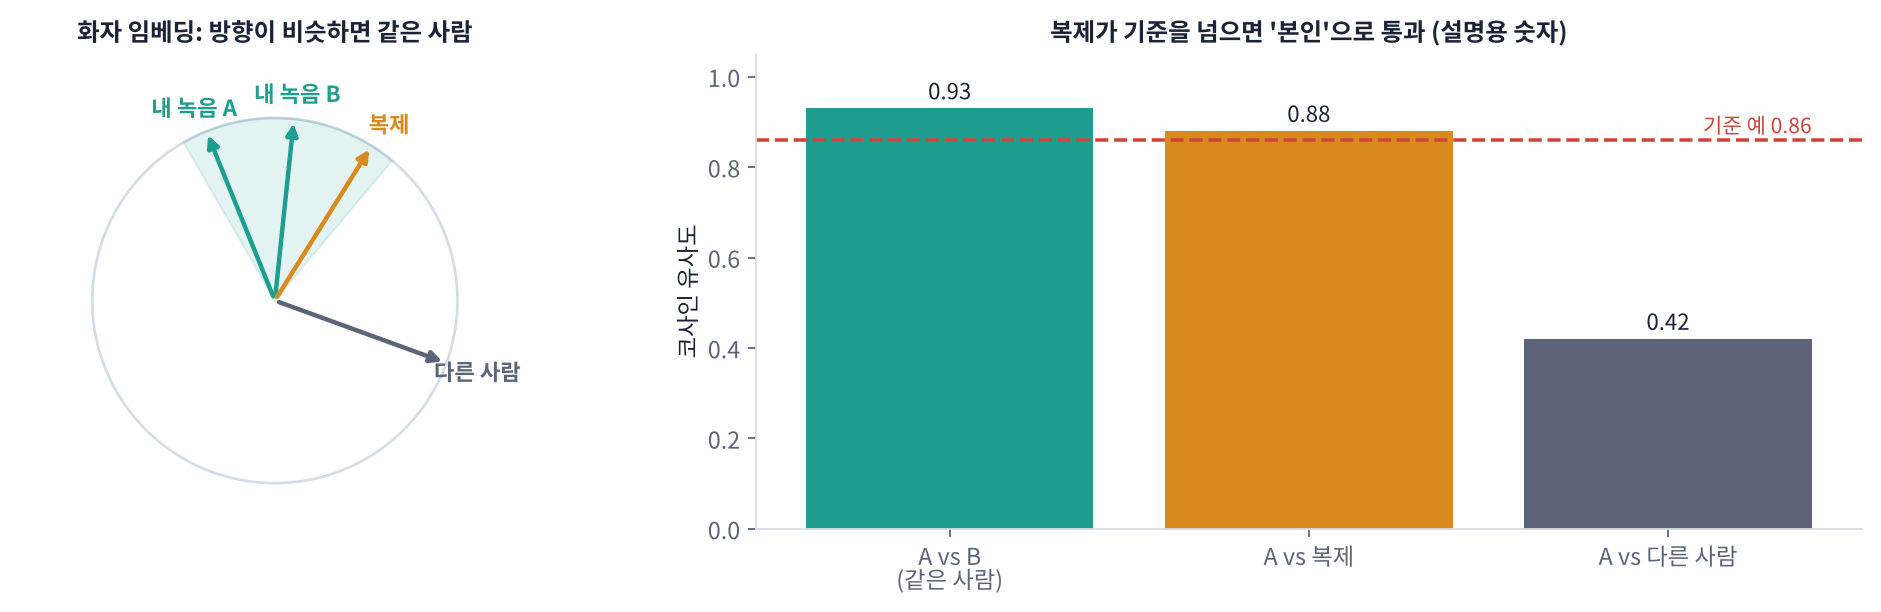

| 비교 | 기대 |
|---|---|
| 참고 녹음 vs 확인용 녹음 (같은 사람 · 다른 문장) | 기준 위 |
| 확인용 녹음 vs **복제** | 기준 위면 **인증 우회 가능** |
| 확인용 녹음 vs 다른 사람 | 기준 아래 |
| 복제 vs 다른 사람 | 기준 아래 |

In [ ]:
other = load(f"{WORK}/other_heldout.wav")
pairs = [("참고 vs 확인용 (같은 사람)", y_ref, held), ("확인용 vs 복제 (참고 10초)", held, len_wavs[10]),
         ("확인용 vs 복제 (참고 3초)", held, len_wavs[3]), ("확인용 vs 다른 사람", held, other), ("복제 vs 다른 사람", len_wavs[10], other)]
rows = [dict(비교=n, 유사도=round(sim(a, b), 3), 같은_사람_판정=same_speaker(sim(a, b))) for n, a, b in pairs]
SV_TABLE = pd.DataFrame(rows)
display(SV_TABLE)

fig, ax = plt.subplots(figsize=(10, 3))
cols = ["tab:green", "tab:orange", "tab:orange", "tab:gray", "tab:gray"]
ax.barh([r["비교"] for r in rows][::-1], [r["유사도"] for r in rows][::-1], color=cols[::-1])
ax.axvline(SV_THRESHOLD, color="red", ls="--"); ax.set_xlabel("cosine similarity (red = threshold)"); ax.set_xlim(min(0, min(r["유사도"] for r in rows)), 1)
ax.set_yticklabels(["same person", "clone 10s", "clone 3s", "other person", "clone vs other"][::-1]); plt.tight_layout(); plt.show()

**결과 읽기**
- **복제가 기준을 넘었다면**: 이 화자 인증만 쓰는 시스템은 복제 목소리를 본인으로 받아들입니다. 넘지 못했더라도 '같은 사람'과 '다른 사람' 사이 어디쯤인지 보세요. 모델이 좋아질수록 복제 막대는 같은 사람 쪽으로 이동합니다.
- **기준을 높이면?** 복제는 막히지만 진짜 본인도 자주 거부됩니다(감기 · 잡음 · 다른 마이크). 기준 하나로 둘 다 잡기 어렵습니다.

👣 **그래서 실무에서는 여러 겹으로**
1. 목소리 인증은 **보조 수단**으로만 (단독 인증 금지)
2. **무작위 문장 읽기**(매번 다른 문장, 시간 제한) → 미리 만든 복제 녹음 재생을 어렵게 함. 단, 실시간 음성 변환(VC)에는 약함
3. **합성 음성 탐지(anti-spoofing)** 모델 · 워터마크 검사 추가 (ASVspoof 같은 공개 대회 · 데이터가 있음)
4. 중요한 거래는 **다른 경로로 재확인**(앱 푸시, 등록된 번호로 다시 걸기)

**❓ 생각해 보기**: 가족에게서 '급하게 돈이 필요하다'는 전화가 왔고 목소리가 똑같습니다. 개인이 할 수 있는 가장 확실한 확인 방법은?

<details>
<summary>답 보기</summary>

전화를 끊고 **내가 알고 있는 번호로 다시 걸어** 확인하는 것입니다(다른 경로 재확인). 가족끼리만 아는 **확인 질문 · 암호**를 미리 정해 두는 것도 좋습니다. 목소리가 똑같다는 것은 더 이상 본인이라는 증거가 아닙니다. 오늘 실습이 보여 준 것처럼, 몇 초의 공개 녹음으로도 비슷한 목소리를 만들 수 있기 때문입니다.

</details>

## Part 5. 워터마크는 얼마나 버티나

> 💬 **쉽게 말하면**: D18에서 Chatterbox가 만든 소리에는 Perth 워터마크가 들어 있었습니다. 그런데 소리는 **전화로 전달되고, 메신저에서 압축되고, 잡음이 섞이고, 편집**됩니다. 이런 변형 뒤에도 표시가 남는지 직접 공격해 봅니다. 인공지능기본법 · EU AI Act가 요구하는 '표시'가 실제로 어느 정도 믿을 만한지 아는 것이 목표입니다.

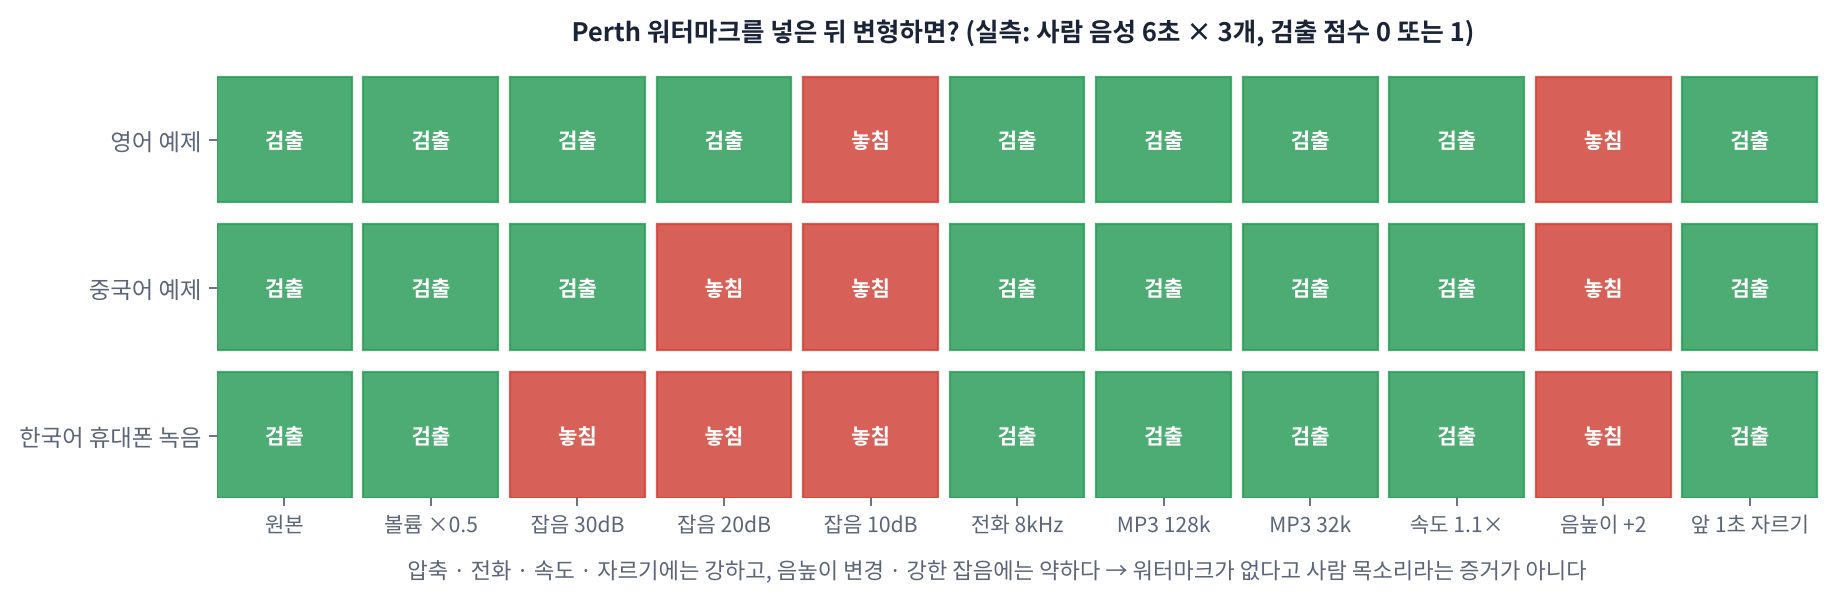

👣 **오늘의 변형(공격)**
1. **볼륨** ×0.5 · **앞 1초 자르기** — 편집
2. **잡음** 30 · 20 · 10 dB SNR — 시끄러운 곳에서 재녹음
3. **전화** — 8 kHz로 내렸다 올리기(4 kHz 위 소리가 사라짐)
4. **MP3** 128 · 32 kbps — 메신저 · 웹 압축
5. **속도 1.1배** · **음높이 +2반음** — 의도적인 지우기 시도

> 📐 **핵심 식 하나: SNR(dB) = 10 · log₁₀(신호 전력 ÷ 잡음 전력)** — 20 dB = 잡음 전력이 신호의 1/100, 10 dB = 1/10

> 🍎 **비유: 지폐의 숨은 그림.** 복사기(압축) · 구김(잡음) · 축소(전화)를 거쳐도 숨은 그림이 보이는지 시험하는 것과 같습니다. 숨은 그림이 없다고 진짜 지폐인 것은 아닙니다(다른 위조 방법).

> 🎬 **애니메이션 D19-6:** [워터마크 공격 실험실](https://imguru-mooc.github.io/AI_Voice/day19/animation.html#wm) — 변형을 켜고 끄며 실측 검출 결과와 이유 보기
> 🎬 **애니메이션 D19-8:** [SNR 계산기](https://imguru-mooc.github.io/AI_Voice/day19/animation.html#snr) — 잡음 크기를 바꿔 SNR과 파형 · 잡음 전력 비율 보기

### 🧩 빈칸 실습 7 · 8: 잡음과 전화 변형 만들기
- 빈칸 7: 원하는 SNR(dB)이 되도록 잡음 크기를 맞추는 식. 전력비 = 10^(SNR ÷ **?**)
- 빈칸 8: 전화 음질(협대역)의 **샘플링 레이트** (Hz)

In [ ]:
# 🧩 빈칸 실습 7 · 8
import perth
WM = perth.PerthImplicitWatermarker()

def add_noise(y, snr_db, seed=0):
    n = np.random.default_rng(seed).standard_normal(len(y)).astype(np.float32)
    p_sig, p_noise = np.mean(y ** 2), np.mean(n ** 2)
    return y + n * np.sqrt(p_sig / (p_noise * 10 ** (snr_db / ____)))                    # 빈칸 7

def phone(y, sr=SR):
    y8 = librosa.resample(y, orig_sr=sr, target_sr=____)                                  # 빈칸 8
    return librosa.resample(y8, orig_sr=8000, target_sr=sr)[: len(y)]

def mp3(y, kbps, sr=SR):
    sf.write(f"{WORK}/_t.wav", y, sr)
    subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", f"{WORK}/_t.wav", "-b:a", f"{kbps}k", f"{WORK}/_t.mp3"], check=True)
    return load(f"{WORK}/_t.mp3", sr)

ATTACKS = {"원본": lambda y: y, "볼륨 ×0.5": lambda y: 0.5 * y, "앞 1초 자르기": lambda y: y[SR:],
           "잡음 30dB": lambda y: add_noise(y, 30), "잡음 20dB": lambda y: add_noise(y, 20), "잡음 10dB": lambda y: add_noise(y, 10),
           "전화 8kHz": phone, "MP3 128k": lambda y: mp3(y, 128), "MP3 32k": lambda y: mp3(y, 32),
           "속도 1.1×": lambda y: librosa.effects.time_stretch(y, rate=1.1), "음높이 +2": lambda y: librosa.effects.pitch_shift(y, sr=SR, n_steps=2)}

# 확인: 실제 SNR과 4 kHz 위 에너지
y_test = load(f"{WORK}/clone.wav")
noisy = add_noise(y_test, 20)
snr_measured = 10 * np.log10(np.mean(y_test ** 2) / np.mean((noisy - y_test) ** 2))
spec = np.abs(np.fft.rfft(phone(y_test))) ** 2; freqs = np.fft.rfftfreq(len(y_test), 1 / SR)
hi_ratio = spec[freqs > 4200].sum() / spec.sum()
print(f"잡음 20 dB 목표 → 실제 {snr_measured:.2f} dB · 전화 변형 후 4.2 kHz 위 에너지 비율 {hi_ratio:.5f}")
check(abs(snr_measured - 20) < 0.2 and hi_ratio < 0.01, hint="빈칸 7 = 10, 빈칸 8 = 8000")

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
return y + n * np.sqrt(p_sig / (p_noise * 10 ** (snr_db / 10)))
y8 = librosa.resample(y, orig_sr=sr, target_sr=8000)
```

**해설**: SNR은 **전력** 비율의 dB이므로 10 · log₁₀입니다. 거꾸로 dB → 전력비는 10^(dB ÷ 10)이고, 잡음 전력을 신호 전력 ÷ 그 비율로 맞추려면 진폭에 제곱근을 곱합니다(전력 = 진폭²). (진폭 비율의 dB는 20 · log₁₀입니다. 섞어 쓰면 틀립니다.) 전화망은 **8 kHz**로 샘플링해 나이퀴스트 주파수 4 kHz 위 소리가 사라집니다. 그래서 8 kHz로 내렸다 올리면 4 kHz 위 에너지가 거의 0이 됩니다(D2 · D26과 연결).

</details>

### 5-1. 실험: 복제 · 내 녹음 · 워터마크를 넣은 내 녹음
세 소리에 모든 변형을 걸고 Perth 검출 점수(0 = 없음, 1 = 있음)를 표로 만듭니다.
- **복제**: Chatterbox가 이미 워터마크를 넣음 → 변형 후에도 1이 나와야 좋음
- **내 녹음(원본)**: 워터마크 없음 → 0이 나와야 함(**거짓 경보** 확인)
- **내 녹음 + 워터마크**: 사람 녹음에 직접 넣은 경우

In [ ]:
mine = load(MY_HELD)
mine_wm = WM.apply_watermark(mine, sample_rate=SR)
SOURCES = {"복제 (Chatterbox)": load(f"{WORK}/clone.wav"), "내 녹음 (원본)": mine, "내 녹음 + 워터마크": mine_wm}
table = {}
for src, y in SOURCES.items():
    table[src] = {a: round(float(WM.get_watermark(f(y).astype(np.float32), sample_rate=SR)), 2) for a, f in ATTACKS.items()}
WM_TABLE = pd.DataFrame(table).T
display(WM_TABLE)

fig, ax = plt.subplots(figsize=(12, 2.6))
ax.imshow(WM_TABLE.values, cmap="RdYlGn", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(ATTACKS))); ax.set_xticklabels(["orig", "vol", "crop", "n30", "n20", "n10", "phone", "mp3-128", "mp3-32", "speed", "pitch"], fontsize=9)
ax.set_yticks(range(3)); ax.set_yticklabels(["clone", "my voice", "my voice + WM"])
for i in range(WM_TABLE.shape[0]):
    for j in range(WM_TABLE.shape[1]):
        ax.text(j, i, f"{WM_TABLE.values[i, j]:.0f}" if WM_TABLE.values[i, j] in (0, 1) else f"{WM_TABLE.values[i, j]:.2f}", ha="center", va="center")
plt.tight_layout(); plt.show()
play(ATTACKS["음높이 +2"](SOURCES["복제 (Chatterbox)"]), SR, "음높이 +2반음 변형 (워터마크가 사라지기 쉬움)")

**결과 읽기** (강사 실측 예: 사람 음성 3개에 워터마크를 넣고 변형 → 위 그림)
- 볼륨 · 자르기 · 전화 · MP3 · 속도 1.1배에는 대체로 **강하고**, **음높이 변경**과 **강한 잡음(20 dB 이하)** 에는 **약한** 경향입니다. 여러분의 표도 같은 경향인지 확인하세요.
- **내 녹음(원본)** 줄이 모두 0이면 거짓 경보가 없는 것입니다.
- 결론: 워터마크는 '정직한 서비스가 만든 소리'를 확인하는 데는 유용하지만, **나쁜 의도로 변형하거나 워터마크를 넣지 않는 모델**로 만든 소리는 잡지 못합니다. 그래서 법은 워터마크(표시) 의무와 함께 **고지 · 동의 · 처벌**을 함께 둡니다.

> 🎬 **애니메이션 D19-9:** [전화 음질 시뮬레이터](https://imguru-mooc.github.io/AI_Voice/day19/animation.html#phone) — 샘플링 레이트를 내리면 어떤 주파수가 사라지는지 스펙트럼으로 보기

**❓ 생각해 보기**: 워터마크를 지우는 방법을 공개적으로 실험 · 발표하는 것은 나쁜 일일까요?

<details>
<summary>답 보기</summary>

방어 기술은 **약점을 알아야** 좋아집니다. 그래서 워터마크 · 탐지 연구는 공격 실험을 공개해 비교합니다(오늘처럼). 다만 실험은 **자신이 만든 소리 · 공개 데이터**로 하고, 특정 서비스의 탐지를 피하는 도구를 배포하거나 실제 사칭에 쓰는 것은 다른 문제입니다. 연구 공개와 악용 도구 배포의 경계를 의식하는 것이 연구 윤리입니다.

</details>
---
### 📝 3교시 마무리: 개념 워크시트

> **[worksheet.html 열기 → 3교시 탭](https://imguru-mooc.github.io/AI_Voice/day19/worksheet.html)** — 화자 인증과 복제, 기준값의 딜레마, 다중 인증 · 무작위 문장, SNR 식, 전화 8 kHz, 워터마크가 강한 · 약한 변형, 거짓 경보
>
> 10문항을 풀고 **채점하기**를 누르세요.

## Part 6. 책임 있는 복제 함수 만들기

> 💬 **쉽게 말하면**: 지금까지 배운 안전장치를 **함수 하나**로 묶습니다. 요청이 오면 ① 동의 기록이 있고 · 만료 전이며 · **철회되지 않았는지** ② 금지된 내용(송금 · 비밀번호 요구 등)인지 확인한 뒤 ③ 합성하고 ④ 앞에 **"AI로 만든 음성입니다" 고지**를 붙이고 ⑤ 워터마크를 확인하고 ⑥ **로그**를 남깁니다. 하나라도 실패하면 소리를 내보내지 않습니다.

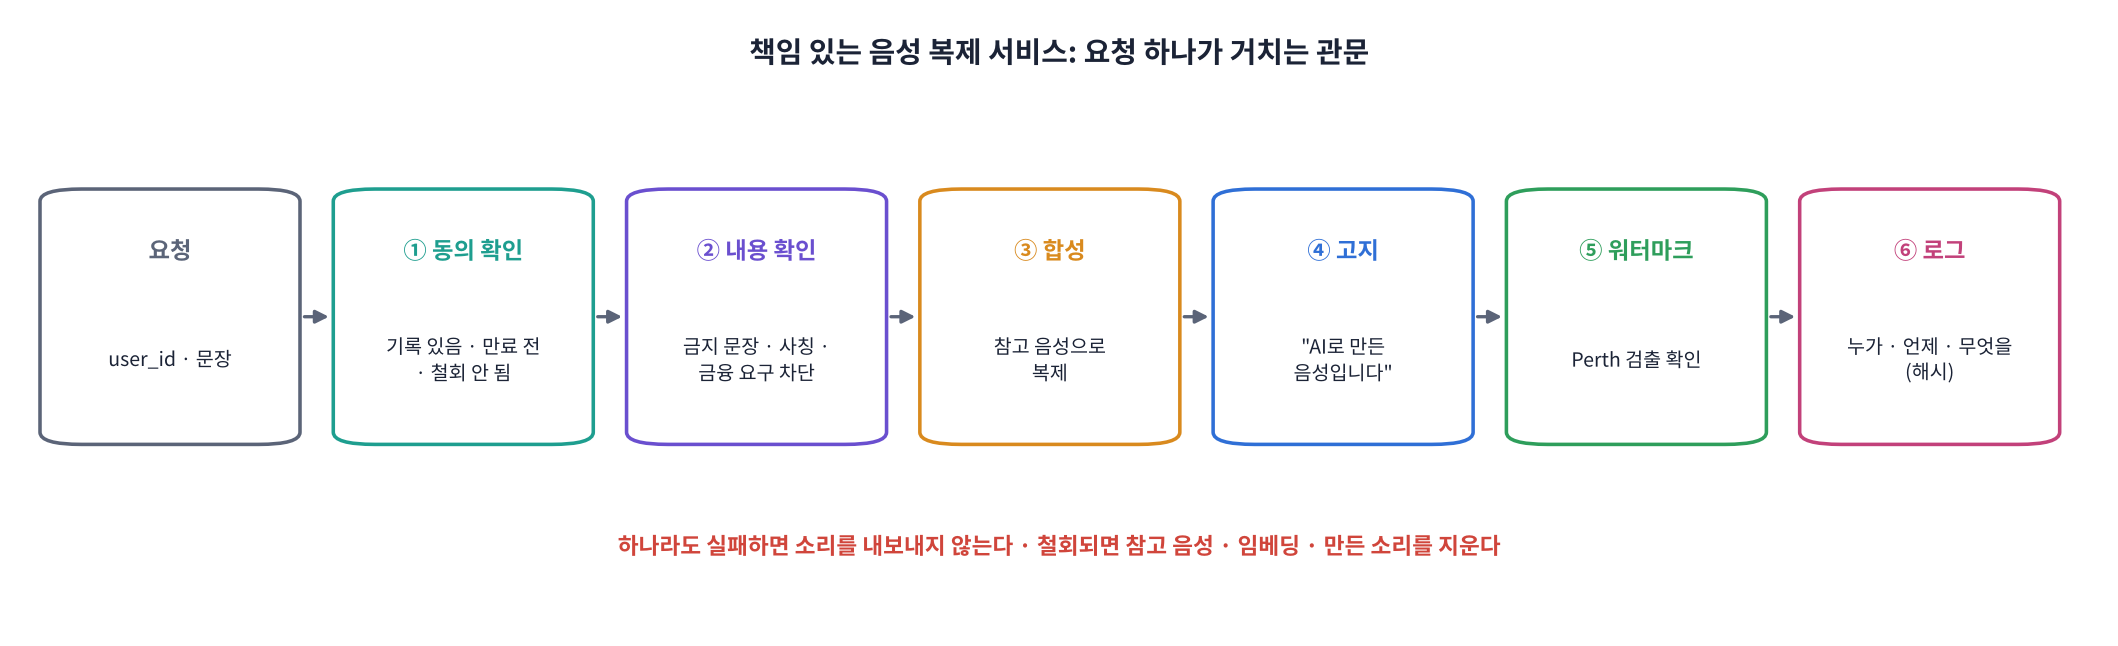

| 관문 | 근거 |
|---|---|
| 동의 · 만료 · **철회** | 개인정보 처리 원칙(목적 · 기간 · 철회권), 퍼블리시티 |
| 금지 내용 차단 | 사칭 · 사기 방지 (예: 송금 · 계좌 · 인증번호 요구) |
| 고지 문구 | 인공지능기본법 · EU AI Act의 딥페이크 고지 |
| 워터마크 확인 | 기계 판독 표시 의무 |
| 로그 (해시) | 사고 시 추적 · 책임, 내용 원문 대신 해시로 개인정보 최소화 |

> 🎬 **애니메이션 D19-7:** [요청이 관문을 지나는 과정](https://imguru-mooc.github.io/AI_Voice/day19/animation.html#layers) — 요청 종류를 골라 어느 관문에서 멈추는지 보기

### 🧩 빈칸 실습 9: 철회된 동의는 거부하기
동의 기록(`RECORD`)에는 `revoked`(철회 여부) 항목이 있습니다. 철회된 동의로는 절대 합성하지 않도록, 빈칸에 **철회 여부 키 이름**을 넣으세요. 아래에서 ① 정상 요청 ② 금지 내용 ③ 철회 후 요청을 차례로 시험합니다.

In [ ]:
# 🧩 빈칸 실습 9
CONSENTS = {USER_ID: copy.deepcopy(RECORD)}
REF_OF = {USER_ID: MY_REF}
BLOCK_WORDS = ["송금", "계좌", "비밀번호", "인증번호", "급하게 돈"]
DISCLOSURE = "이 음성은 인공지능으로 만든 음성입니다."
LOG = []

def responsible_clone(user_id, text):
    c = CONSENTS.get(user_id)
    if c is None:
        raise PermissionError("동의 기록 없음")
    if c[____]:                                                                           # 빈칸 9
        raise PermissionError("동의가 철회됨")
    if any(w in text for w in BLOCK_WORDS):
        raise PermissionError("금지된 내용 (사칭 · 금융 요구)")
    if not c["gate"]["ok"]:
        raise PermissionError("동의 확인 실패 (동의 게이트 미통과)")
    if datetime.now() > datetime.fromisoformat(c["expires"]):
        raise PermissionError("동의 만료")
    model.conds = copy.deepcopy(BUILTIN); set_seed(0)
    notice = to_np(model.generate(DISCLOSURE, language_id="ko"))            # 고지는 모델 기본 목소리로
    set_seed(0)
    speech = to_np(model.generate(text, language_id="ko", audio_prompt_path=REF_OF[user_id]))
    model.conds = copy.deepcopy(BUILTIN)
    out = WM.apply_watermark(np.concatenate([notice, np.zeros(int(0.4 * SR), np.float32), speech]), sample_rate=SR)
    if WM.get_watermark(out, sample_rate=SR) < 0.5:
        raise RuntimeError("워터마크 확인 실패 → 내보내지 않음")
    LOG.append(dict(time=datetime.now().isoformat(timespec="seconds"), user_id=user_id,
                    text_sha256=hashlib.sha256(text.encode()).hexdigest()[:16], audio_sha256=hashlib.sha256(out.tobytes()).hexdigest()[:16]))
    return out

def attempt(label, user_id, text):
    try:
        y = responsible_clone(user_id, text)
        print(f"✅ {label}: 합성됨 ({len(y) / SR:.1f}초)"); play(y, SR, label); return "합성"
    except (PermissionError, RuntimeError) as e:
        print(f"⛔ {label}: {e}"); return str(e)

r1 = attempt("① 정상 요청", USER_ID, "오늘 수업 정말 재미있었어요. 다음 시간에 또 만나요.")
r2 = attempt("② 금지 내용", USER_ID, "엄마, 급하게 돈이 필요해서 그러는데 계좌로 송금해 줘.")
CONSENTS[USER_ID]["revoked"] = True                      # 학생이 동의를 철회
r3 = attempt("③ 철회 후 요청", USER_ID, "오늘 수업 정말 재미있었어요.")
display(pd.DataFrame(LOG))
check("철회" in r3 and "금지" in r2, hint='빈칸 9 = "revoked"')

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
if c["revoked"]:
    raise PermissionError("동의가 철회됨")
```

**해설**: 동의는 **언제든 철회**할 수 있어야 하고, 철회 즉시 합성이 멈춰야 합니다. 검사 순서도 중요합니다. 기록 없음 → 철회 → 금지 내용 → 게이트 → 만료 순으로, **가장 확실한 거부 사유**를 먼저 확인하고 비싼 합성은 맨 뒤에 둡니다. ①이 '동의 확인 실패'로 거부되었다면 Part 2의 게이트를 통과하지 못한 것입니다. 이것도 함수가 **제대로** 동작한 것입니다(통과하지 못한 동의로는 만들지 않음). 실제 서비스에서는 철회 시 참고 음성 · 임베딩 · 만든 소리까지 **삭제**하고, 로그에는 원문 대신 **해시**만 남겨 개인정보를 줄입니다. 금지어 목록은 간단한 예시일 뿐이고, 실제로는 분류 모델 · 사람 검토를 함께 씁니다.

</details>

**❓ 생각해 보기**: 금지어 목록에 '송금'을 넣으면 '송금 사기 예방 교육 음성'도 막힙니다. 어떻게 해야 할까요?

<details>
<summary>답 보기</summary>

단어 목록은 **거짓 차단**(좋은 요청을 막음)과 **우회**(띄어쓰기 · 다른 표현)에 모두 약합니다. 그래서 ① 문맥을 보는 분류 모델(LLM 포함)로 '요구 · 사칭 의도'를 판정하고 ② 애매하면 **사람 검토**로 넘기며 ③ 교육 · 공익 목적은 별도 승인 경로를 둡니다. 차단 정책은 '무엇을 막을지'보다 '막혔을 때 사용자가 어떻게 이의를 제기하는지'까지 설계해야 합니다.

</details>

## Part 7. 정리 · 삭제 · 과제

### 🗑️ 녹음 · 복제 파일 삭제 (꼭 실행)
오늘의 약속대로 `voice19/` 폴더의 녹음 · 복제 · 변형 파일을 모두 지웁니다. 동의 기록(JSON)에는 해시만 남아 있어 원본 없이도 '어떤 파일이었는지'는 확인할 수 있습니다.

In [ ]:
DELETE_NOW = True                                        # 수업 후 반드시 True로 실행
if DELETE_NOW:
    n = len(os.listdir(WORK)) if os.path.isdir(WORK) else 0
    shutil.rmtree(WORK, ignore_errors=True)
    for name in ["clone", "mine", "mine_wm", "held", "y_ref", "len_wavs", "SOURCES", "noisy", "y_test", "other", "ref_y"]:
        globals().pop(name, None)
    print(f"🗑️ {n}개 파일 삭제 · 메모리의 소리 변수 정리 완료 → 남은 폴더: {os.path.isdir(WORK)}")
print("남은 동의 기록 (해시만):", json.dumps({k: v["audio_sha256"][:16] + "…" for k, v in CONSENTS.items()}, ensure_ascii=False))

### 오늘 배운 것
| 개념 | 한 줄 정리 | 코드 |
|---|---|---|
| zero-shot 복제 | 참고 음성 몇 초로 학습 없이 복제 | `generate(..., audio_prompt_path=MY_REF)` |
| 법 · 제도 | 표시 · 고지(AI기본법 · EU 50조), 퍼블리시티(타목), 선거(82조의8), 개인정보 | — |
| 화자 인증 | x-vector 코사인 유사도 ≥ 기준 | `sv(**x).embeddings`, `score >= SV_THRESHOLD` |
| 동의 게이트 | 같은 사람 **AND** 동의 문장 | `ok = text_ok and voice_ok` |
| 동의 기록 | 목적 · 범위 · 만료 · 철회 · 해시 | `hashlib.sha256(audio_bytes)` |
| 참고 길이 | 3초도 기준 근처, 길수록 대체로 더 닮음 | `y[: int(sec * SR)]` |
| 화자 인증의 한계 | 복제가 통과 가능 → 다중 인증 · 재확인 | — |
| 워터마크 견고성 | 압축 · 전화엔 강, 음높이 · 강한 잡음엔 약 | `10 ** (snr / 10)`, `target_sr=8000` |
| 책임 있는 함수 | 동의 · 철회 · 내용 · 고지 · 워터마크 · 로그 | `if c["revoked"]: raise` |

### 📝 과제
1. **동의서 설계**: 오늘의 동의 기록 JSON을 바탕으로, 실제 '오디오북 낭독자 목소리 복제' 서비스용 동의서 항목(목적 · 범위 · 기간 · 보상 · 철회 방법 · 파기)을 1쪽 이내로 작성하세요.
2. **견고성 보고서**: Part 5 표를 붙이고, 워터마크가 사라진 변형 두 가지와 그 이유(추측), 서비스에서 보완할 방법을 쓰세요.
3. **정책 토론**: '고인의 목소리를 복원해 가족에게 들려주는 서비스'의 찬성 · 반대 근거를 각각 3개씩, 필요한 안전장치와 함께 정리하세요.

### ✅ 개념 워크시트 제출
4교시 탭까지 모두 채점했다면 오늘 내용을 정리해 제출합니다.

> 📝 **[D19 개념 워크시트 열기](https://imguru-mooc.github.io/AI_Voice/day19/worksheet.html)** — 4교시 × 10문항 (객관식 5 · OX 2 · 선잇기 1 · 순서 맞추기 1 · 모두 고르기 1)

**제출 방법 (노션)**
1. 4개 교시 탭을 모두 채점합니다.
2. **제출** 버튼을 눌러 오답 정리를 엽니다.
3. **📋 캡처 (노션용 복사)** 를 누른 뒤, 노션 제출 페이지에서 `Ctrl + V`로 붙여 넣습니다. **Part 2 게이트 표 · Part 4 화자 인증 표 · Part 5 워터마크 표**도 함께 붙이세요. **소리 파일은 제출하지 않습니다.**

> 🎬 복습용: [애니메이션 전체 보기](https://imguru-mooc.github.io/AI_Voice/day19/animation.html) — D19-1 ~ D19-9

### 다음 시간 (D20 · TTS 평가 + 미니 프로젝트)
4주차를 마무리합니다. **MOS**(사람 청취 평가), **UTMOS**(자동 품질 점수), **ASR 역검증(CER)**, **Streaming TTS** 지연을 함께 재는 평가 틀을 만들고, 미니 프로젝트로 **오디오북 / 안내방송 생성기**를 만듭니다. 오늘의 동의 · 고지 · 워터마크를 생성기에 그대로 붙입니다.